In [1]:
# Libraries:
import numpy as np
import matplotlib.pyplot as plt
import dill
import sys
import os

import pysindy as ps
import D_CODE

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..'))) # include parent directory in the path
from data import SINDy_data
from data import data
from data import equations

from toolbox.auxiliary_functions import SRT_simulation, D_CODE_simulation, set_param_freq

# Seed:
np.random.seed(999)

/home/mattg/miniforge3/envs/SimbSINDy_env/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


#### Case $\mu$, $A$ fixed and $\omega$ varying
Consider the modified Van der Pol system with a nonlinear forcing term
$$
\begin{cases}
\dot{x}_0 = \mu x_0 - x_1 - \mu x_0 x_1^2 + A\sin(\omega x_1^2) \\
\dot{x}_1 = x_0
\end{cases}
$$
and with $\mu=1$, $A=1$ fixed, and $\omega \in [1,\pi]$.

In [2]:
# Select ODE & settings:
ode_name = 'OscilVdpODE_par_w' # help="name of the ode", type=str
ode_param = None # '1.,1.,1.' # help="parameters of the ode (default: None)", type=str, default=None
freq = 10 # help="sampling frequency", type=float, default=10
n_sample = 50 # help="number of trajectories", type=int, default=100
noise_ratio = 0.01 # help="noise level (default 0)", type=float, default=0.
seed = 103 # help="random seed", type=int, default=0
n_seed = 1 # help="random seed", type=int, default=10

ode_param, freq = set_param_freq(ode_param, freq)

ode = equations.get_ode(ode_name, ode_param)
dt = 1 / freq
dim_x = 2
dim_k = 1
time_vector = np.arange(0, ode.T + dt, dt)
T = ode.T

#### SR-T run

> **Remark.** Before running the experiments, make sure that the following settings are correctly configured in the `D_CODE` library:
>
> * In `config.py`, set:
>
>   ```python
>   n_generations = 20
>   functions_set = {'neg': 1, 'mul': 2, 'add': 1, 'sub': 1, 'sin': 1}
>   parsimony_coefficient = 0.004 
>   ```
> * In `gp_utils.py`, uncomment the line of code responsible for extracting the Oscillating Van der Pol ODE .

In [3]:
# running SR-T:
building_blocks_lambda0, function_names0 = SRT_simulation(ode_name, ode_param, 0, freq, n_sample, noise_ratio, alg='tv', seed=seed, n_seed=n_seed, T=T)
building_blocks_lambda1, function_names1 = SRT_simulation(ode_name, ode_param, 1, freq, n_sample, noise_ratio, alg='tv', seed=seed, n_seed=n_seed, T=T)

Running with: ode_name=OscilVdpODE_par_w, ode_param=None, x_id=0, freq=10, n_sample=50, noise_sigma=0.01, alg=tv, seed=103, n_seed=1
Dataset shape:  (101, 50, 3)
Functions set:  {'neg': 1, 'mul': 2, 'add': 1, 'sub': 1, 'sin': 1}
 
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    14.66          83.5706       24         0.819833         0.827155      4.09m
   1     5.86          1.64059       23         0.688259         0.745399      3.35m
   2     3.63            1.489       23         0.691841         0.713154      3.07m
   3     5.40          1.45887       28         0.685486         0.661521      3.16m
   4     6.33          1.44224       28         0.680364         0.707617      3.08m
   5     7.02           1.4151       23         0.562001         0.585968      2.78m
   6     9.54 

##### Plot per report

In [ ]:
from report import evaluate_traj, SRModel_param

# Define the Symbolic Regression model cohirently with the SINDy model
f = lambda x,t,k: [
     x[0]*x[1]*(2.6919317252165063 - x[1]) - 2.75556066802557*x[0]*x[1] + x[0] - x[1] + 0.43466019304941722,
     x[0]
]
model = SRModel_param(f)

In [7]:
# Evaluate RSME on 10 test trajectories
n_test = 10
rmse, _ = SINDy_data.evaluate_RMSE(model, ode, freq, n_test, [1., 1., np.pi], [0., 0., 1.], dim_k)
print('SR-T Model RMSE: ', rmse)

SR-T Model RMSE:  0.9029338988068736


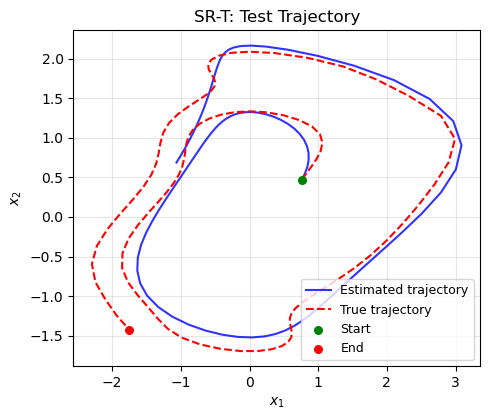

In [8]:
# Simulate a test trajectory starting from an initial condition within the training interval
evaluate_sample = 1
ics = [0.7, 0.4, 2.5]
title = 'SR-T: Test Trajectory'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=10)

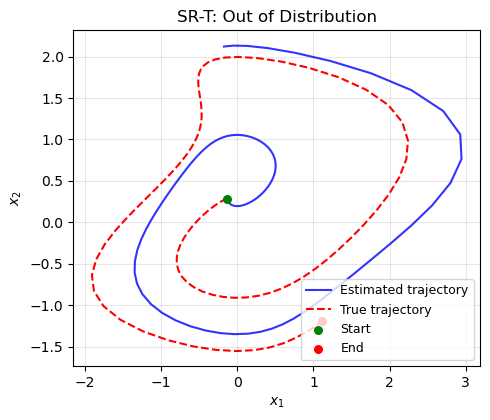

In [9]:
# Simulate a test trajectory starting from an initial condition outside the training interval
evaluate_sample = 1
ics = [-0.1, 0.3, 0.8]
title = 'SR-T: Out of Distribution'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=10)

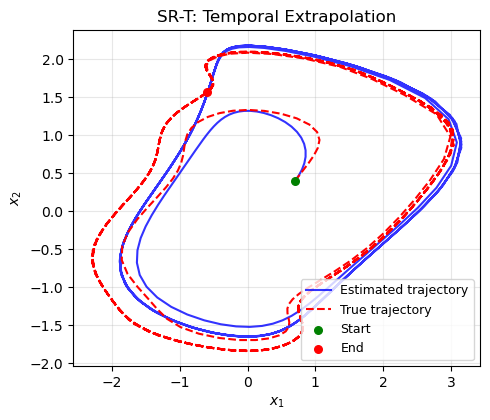

In [10]:
# Simulate a test trajectory starting from an initial condition within the training interval 
# but with focus on a longer extrapolation time
evaluate_sample = 1
ics = [0.7, 0.4, 2.5]
title = 'SR-T: Temporal Extrapolation'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=40)

#### D-CODE run

> **Remark.** Before running the experiments, make sure that the following settings are correctly configured in the `D_CODE` library:
>
> * In `config.py`, set:
>
>   ```python
>   n_generations = 20
>   functions_set = {'neg': 1, 'mul': 2, 'add': 1, 'sub': 1, 'sin': 1}
>   parsimony_coefficient = 0.5 
>   ```
> * In `gp_utils.py`, uncomment the line of code responsible for extracting the Oscillating Van der Pol ODE .

In [3]:
# running D-CODE
building_blocks_lambda0, function_names0 = D_CODE_simulation(ode_name, ode_param, 0, freq, n_sample, noise_ratio, seed=seed, n_seed=n_seed, T=T)
building_blocks_lambda1, function_names1 = D_CODE_simulation(ode_name, ode_param, 1, freq, n_sample, noise_ratio, seed=seed, n_seed=n_seed, T=T)

Running with: ode_name=OscilVdpODE_par_w, ode_param=None, x_id=0, freq=10, n_sample=50, noise_sigma=0.01, seed=103, n_seed=1
Dataset shape:  (201, 50, 3)
Functions set:  {'neg': 1, 'mul': 2, 'add': 1, 'sub': 1, 'sin': 1}
 
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    14.66      3.60984e+10        9          191.505          207.464      4.34m
   1     9.00           186175       23          156.768          128.786      3.27m
   2     3.05          37522.9       23          150.703          183.372      2.81m
 
promising programs:
add(add(add(sub(X0, X1), sin(3.061)), mul(sub(3.325, X1), mul(X0, X1))), neg(mul(mul(1.378, X0), add(X1, X1))))
add(add(add(sub(X0, X1), sin(3.061)), mul(sub(3.325, X1), mul(X0, X1))), neg(mul(mul(1.378, X0), add(X1, X1))))
add(add(add(sub(X0, X1), sin(3.

##### Plot per report

In [4]:
from report import evaluate_traj, SRModel_param

# Define the Symbolic Regression model cohirently with the SINDy model    
f = lambda x,t,k: [
    -2.75556066802557*x[0]*x[1] + x[0]*x[1]*(3.3247875824471675 - x[1]) - x[0]*np.sin(np.sin(x[1])) + x[0] - x[1] + np.sin(k*x[1]**2),
    x[0]
]
model = SRModel_param(f)

In [5]:
# Evaluate RSME on 10 test trajectories
n_test = 10
rmse, _ = SINDy_data.evaluate_RMSE(model, ode, freq, n_test, [1., 1., np.pi], [0., 0., 1], dim_k)
print('D-CODE Model RMSE: ', rmse)

D-CODE Model RMSE:  0.4644006524973011


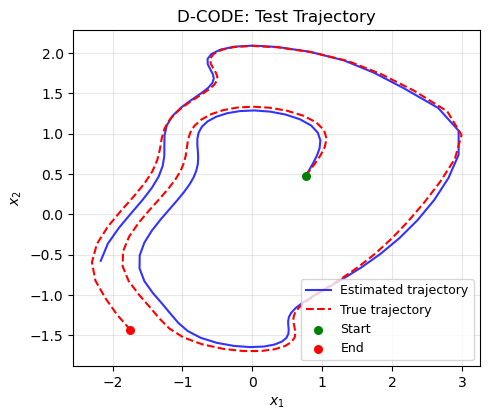

In [6]:
# Simulate a test trajectory starting from an initial condition within the training interval
evaluate_sample = 1
ics = [0.7, 0.4, 2.5]
title = 'D-CODE: Test Trajectory'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=10)

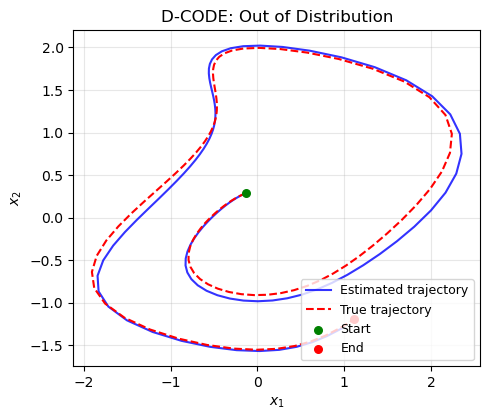

In [7]:
# Simulate a test trajectory starting from an initial condition outside the training interval
evaluate_sample = 1
ics = [-0.1, 0.3, 0.8]
title = 'D-CODE: Out of Distribution'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=10)

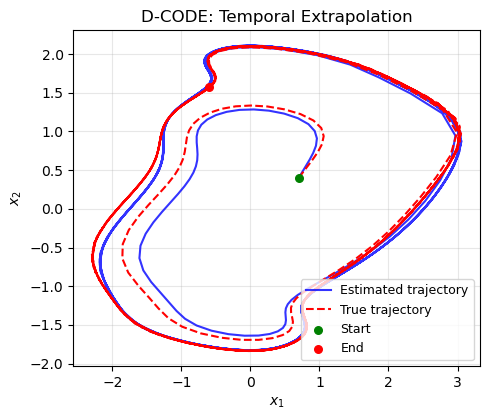

In [8]:
# Simulate a test trajectory starting from an initial condition within the training interval 
# but with focus on a longer extrapolation time
evaluate_sample = 1
ics = [0.7, 0.4, 2.5]
title = 'D-CODE: Temporal Extrapolation'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=40)